In [2]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 53.48,
    "longitude": -2.24,
    "start_date": "2020-01-01",
    "end_date": "2026-11-20",
    "daily": "precipitation_sum",
    "timezone": "Europe/London",
}

response = requests.get(url, params=params)
print(response.status_code)

data = response.json()
rain = pd.DataFrame(data["daily"])
rain.head()

200


,time,precipitation_sum
0,2020-01-01,0.0
1,2020-01-02,3.1
2,2020-01-03,1.4
3,2020-01-04,3.6
4,2020-01-05,0.0


(2516, 2)


<Axes: title={'center': 'Manchester daily rainfall 2020-2026 (mm)'}, xlabel='time'>

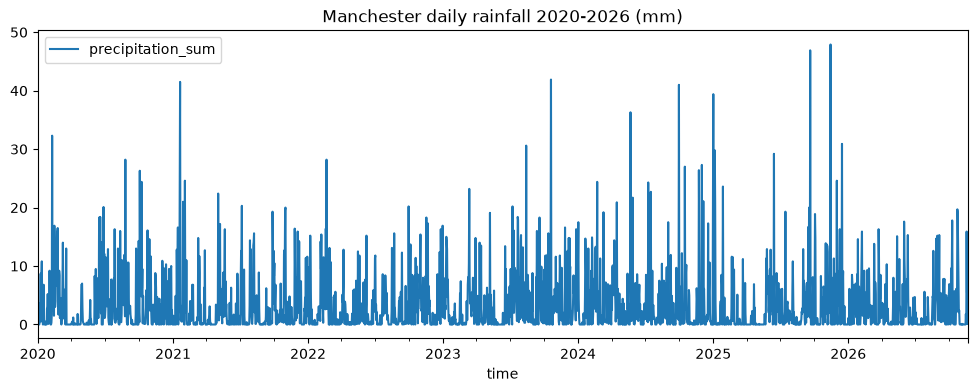

In [4]:
print(rain.shape)
rain["time"] = pd.to_datetime(rain["time"])
rain.plot(x="time", y="precipitation_sum", figsize=(12, 4), title="Manchester daily rainfall 2020-2026 (mm)")

In [5]:
import plotly.express as px

monthly = rain.set_index("time")["precipitation_sum"].resample("MS").sum().reset_index()

fig = px.bar(monthly, x="time", y="precipitation_sum",
             title="Manchester monthly rainfall 2020-2026",
             labels={"time": "Month", "precipitation_sum": "Rainfall (mm)"})
fig.show()

>Key observations: Manchester monthly rainfall (2020–2026)
- **February 2020** had one of the highest monthly totals, driven by Storms Ciara and Dennis, which caused widespread UK flooding.
- **July 2023** was unusually wet for a summer month, with rainfall comparable to the wettest winter months.
- **October 2026** shows the most recent high-rainfall peak in the data.
- Rainfall is highly variable day to day; monthly totals reveal the pattern more clearly than daily values.

In [7]:
rain.to_csv("../data/raw/manchester_rainfall_daily.csv", index=False)
print("Saved", len(rain), "rows")

Saved 2516 rows
